# Spline-state Kalman filter — IV surface

State space: spline coefficients θ ∈ ℝⁿ parametrize the whole smile.  
Each quote from any option yields one scalar observation; the full surface is updated jointly.  
Trades are evaluated out-of-sample against the surface state at their matched quote timestamp.

In [1]:
import importlib as imp
import os
import sys
from datetime import date, datetime

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# shared functions (unchanged from individual filter)
sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)

# new spline-specific modules (to be built alongside this notebook)
sys.path.insert(0, os.path.dirname(os.path.abspath("__file__")))

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["QUANTDATA_CACHE_MODE"] = "on"
os.environ["QUANTDATA_TEST_MODE"] = "0"

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

# shared, unmodified
import surface_kalman_filters  # build_iv_observations + run_spline_surface_kalman

# new spline modules (files to be created in this folder)
import surface_model  # SurfaceModelConfig + basis evaluation

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## Config — change these to experiment

In [2]:
# ── Pick model here ───────────────────────────────────────────────────────────
# surface_model.QUAD_SLICE_MODEL — 3 params, a+b·k+c·k²         linear KF, single expiry
# surface_model.SVI_SLICE_MODEL  — 5 params, SVI raw             EKF,    single expiry
# surface_model.SVI_MODEL        — 5 params, SVI raw × √T        EKF,    multi-expiry
# surface_model.TANH_MODEL       — 3 params, a√T(1+tanh(bk+ck²)) EKF,   multi-expiry
model = surface_model.SVI_SLICE_MODEL

cfg = surface_model.SurfaceModelConfig(
    model=model,
    Q_scale=0.05,  # multiplied by q_diag_weights per parameter
    Q_structure="scaled_identity",
    P0_scale=1.0,
)
print(f"Model     : {cfg.model.name}  |  n_params={cfg.n_params}")
print(f"Initial θ : {cfg.model.initial_theta(cfg)}")
print(f"Q diagonal: {surface_model.build_Q(cfg).diagonal().round(4)}")

Model     : svi_slice  |  n_params=5
Initial θ : [ 5.e-05  5.e-04 -7.e-01  0.e+00  2.e-01]
Q diagonal: [0.05 0.05 0.05 0.05 0.05]


## Data loading

In [3]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [4]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

## Build IV observation stream

`build_iv_observations` runs Phases 1+2 of the existing pipeline (fetch, clean, compute implied forward, compute IV) but stops before any per-option Kalman step.  
It returns two long DataFrames — one for quotes, one for matched trades — each with columns:
`ts_ns, log_moneyness, T, observed_iv, bid_iv, ask_iv, R_iv, strike, is_call`

In [5]:
imp.reload(surface_kalman_filters)
imp.reload(surface_model)

df_quotes_iv, df_trades_iv = surface_kalman_filters.build_iv_observations(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
print(f"Quotes: {df_quotes_iv.shape[0]:,} rows, {df_quotes_iv['strike'].n_unique()} strikes")
print(f"Trades: {df_trades_iv.shape[0]:,} rows")
df_quotes_iv.head()

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
Quotes: 2,115,510 rows, 25 strikes
Trades: 74,099 rows


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43


## Run spline surface Kalman filter

`run_spline_surface_kalman` takes the merged observation stream and config.  
At each quote tick it computes `H = basis(log_moneyness, T)` and runs one KF update on the shared state θ.  
Returns:
- `df_quotes_result` — quotes with `spline_iv` column (surface evaluated at that option's coordinates)
- `df_trades_result` — trades with `spline_matched` and `trade_residual` columns

In [6]:
# OTM filter: keep puts where K < F (k < 0) and calls where K >= F (k >= 0).
# ITM options have wide spreads and their IV is unreliable — exclude from training.
# Trades are kept unfiltered for fair out-of-sample evaluation.
df_quotes_otm = df_quotes_iv.filter(
    (pl.col("is_call") & (pl.col("log_moneyness") >= 0))
    | (~pl.col("is_call") & (pl.col("log_moneyness") < 0))
)
print(f"Quotes before OTM filter: {df_quotes_iv.shape[0]:,}  →  after: {df_quotes_otm.shape[0]:,}")

df_quotes_result, df_trades_result, df_state = surface_kalman_filters.run_spline_surface_kalman(
    df_quotes_iv=df_quotes_otm,
    df_trades_iv=df_trades_iv,
    cfg=cfg,
)
df_quotes_result.head()

Quotes before OTM filter: 2,115,510  →  after: 978,523


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,spline_iv,kalman_price
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,0.136094,0.097232
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,0.138179,0.104955
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,0.138422,0.250424
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,0.137419,0.159995
2024-01-03 09:30:00.008504576 EST,466.0,false,-0.009462,0.006217,0.141883,0.140865,0.142848,9.8379e-7,0.57,0.59,470.43,0.141882,0.580454


In [7]:
df_trades_result.head()

ts_ns,quote_ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,bid_price,ask_price,forward,ts_ns_right,spline_matched,kalman_price,trade_residual
"datetime[ns, America/New_York]","datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,"datetime[ns, America/New_York]",f64,f64,f64
2024-01-03 09:30:00.102 EST,2024-01-03 09:30:00.008504576 EST,466.0,false,-0.009547,0.006217,0.141628,0.141628,0.143618,0.57,0.59,470.47,2024-01-03 09:30:00.008504576 EST,0.1419,0.572787,-0.000272
2024-01-03 09:30:00.311 EST,2024-01-03 09:30:00.008504576 EST,466.0,false,-0.010131,0.006217,0.14783,0.146837,0.148818,0.57,0.59,470.745,2024-01-03 09:30:00.008504576 EST,0.142023,0.522253,0.005807
2024-01-03 09:30:00.031 EST,2024-01-03 09:30:00.031845888 EST,479.0,true,0.01799,0.006217,0.130745,0.130745,0.1441,0.08,0.13,470.46,2024-01-03 09:30:00.031845888 EST,0.13732,0.103192,-0.006576
2024-01-03 09:30:00.051 EST,2024-01-03 09:30:00.044120064 EST,480.0,true,0.020075,0.006217,0.142976,0.139489,0.142976,0.07,0.08,470.46,2024-01-03 09:30:00.044120064 EST,0.13987,0.071081,0.003106
2024-01-03 09:30:00.102 EST,2024-01-03 09:30:00.112472576 EST,463.0,false,-0.016005,0.006217,0.154323,0.149303,0.151009,0.22,0.23,470.47,2024-01-03 09:30:00.112472576 EST,0.150423,0.226672,0.0039


## Quick residual check

In [8]:
df_trades_clean = df_trades_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse = float((df_trades_clean["trade_residual"] ** 2).mean() ** 0.5)
print(f"Trade RMSE (IV): {rmse:.5f}")
print(f"Rows: {df_trades_clean.shape[0]:,}")

Trade RMSE (IV): 0.00362
Rows: 74,099


## Smile snapshot — spline surface vs raw IV

In [9]:
# ── Pick a snapshot ──────────────────────────────────────────────────────────
row_idx = df_quotes_result.shape[0] // 2  # ← change this
snapshot_ts = df_quotes_result["ts_ns"][row_idx]

# θ at the snapshot: last state update at or before snapshot_ts
state_row = df_state.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
theta_snap = np.array([state_row[f"theta_{j}"][0] for j in range(cfg.n_params)])

# Use the median T of options alive at the snapshot time as the reference maturity
snap_quotes = (
    df_quotes_result.filter(pl.col("ts_ns") <= snapshot_ts).group_by(["strike", "is_call"]).last()
)
snap_T = float(snap_quotes["T"].median())

# ── Evaluate the continuous fitted smile ──────────────────────────────────────
k_grid = np.linspace(-0.15, 0.15, 300)
iv_fit = np.array([cfg.model.observe(theta_snap, k, snap_T)[0] for k in k_grid])

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=k_grid,
        y=iv_fit,
        mode="lines",
        name=f"fitted ({cfg.model.name})",
        line=dict(color="darkgreen", width=2),
    )
)
fig.add_trace(
    go.Scatter(
        x=snap_quotes.filter(pl.col("is_call"))["log_moneyness"].to_list(),
        y=snap_quotes.filter(pl.col("is_call"))["observed_iv"].to_list(),
        mode="markers",
        name="calls — observed",
        marker=dict(color="royalblue", symbol="x", size=8),
    )
)
fig.add_trace(
    go.Scatter(
        x=snap_quotes.filter(~pl.col("is_call"))["log_moneyness"].to_list(),
        y=snap_quotes.filter(~pl.col("is_call"))["observed_iv"].to_list(),
        mode="markers",
        name="puts — observed",
        marker=dict(color="firebrick", symbol="x", size=8),
    )
)

fig.update_layout(
    title=f"[{cfg.model.name}] Fitted smile — T={snap_T:.3f}y  |  ts={snapshot_ts}",
    xaxis_title="log-moneyness  k = log(K/F)",
    yaxis_title="Implied Vol",
)
fig.show()
print(f"θ = {dict(zip(['a', 'b', 'rho', 'm', 'sigma'][: cfg.n_params], theta_snap.round(4)))}")

θ = {'a': np.float64(-0.0002), 'b': np.float64(0.0299), 'rho': np.float64(-0.9191), 'm': np.float64(-0.0557), 'sigma': np.float64(0.0268)}


## Full evaluation

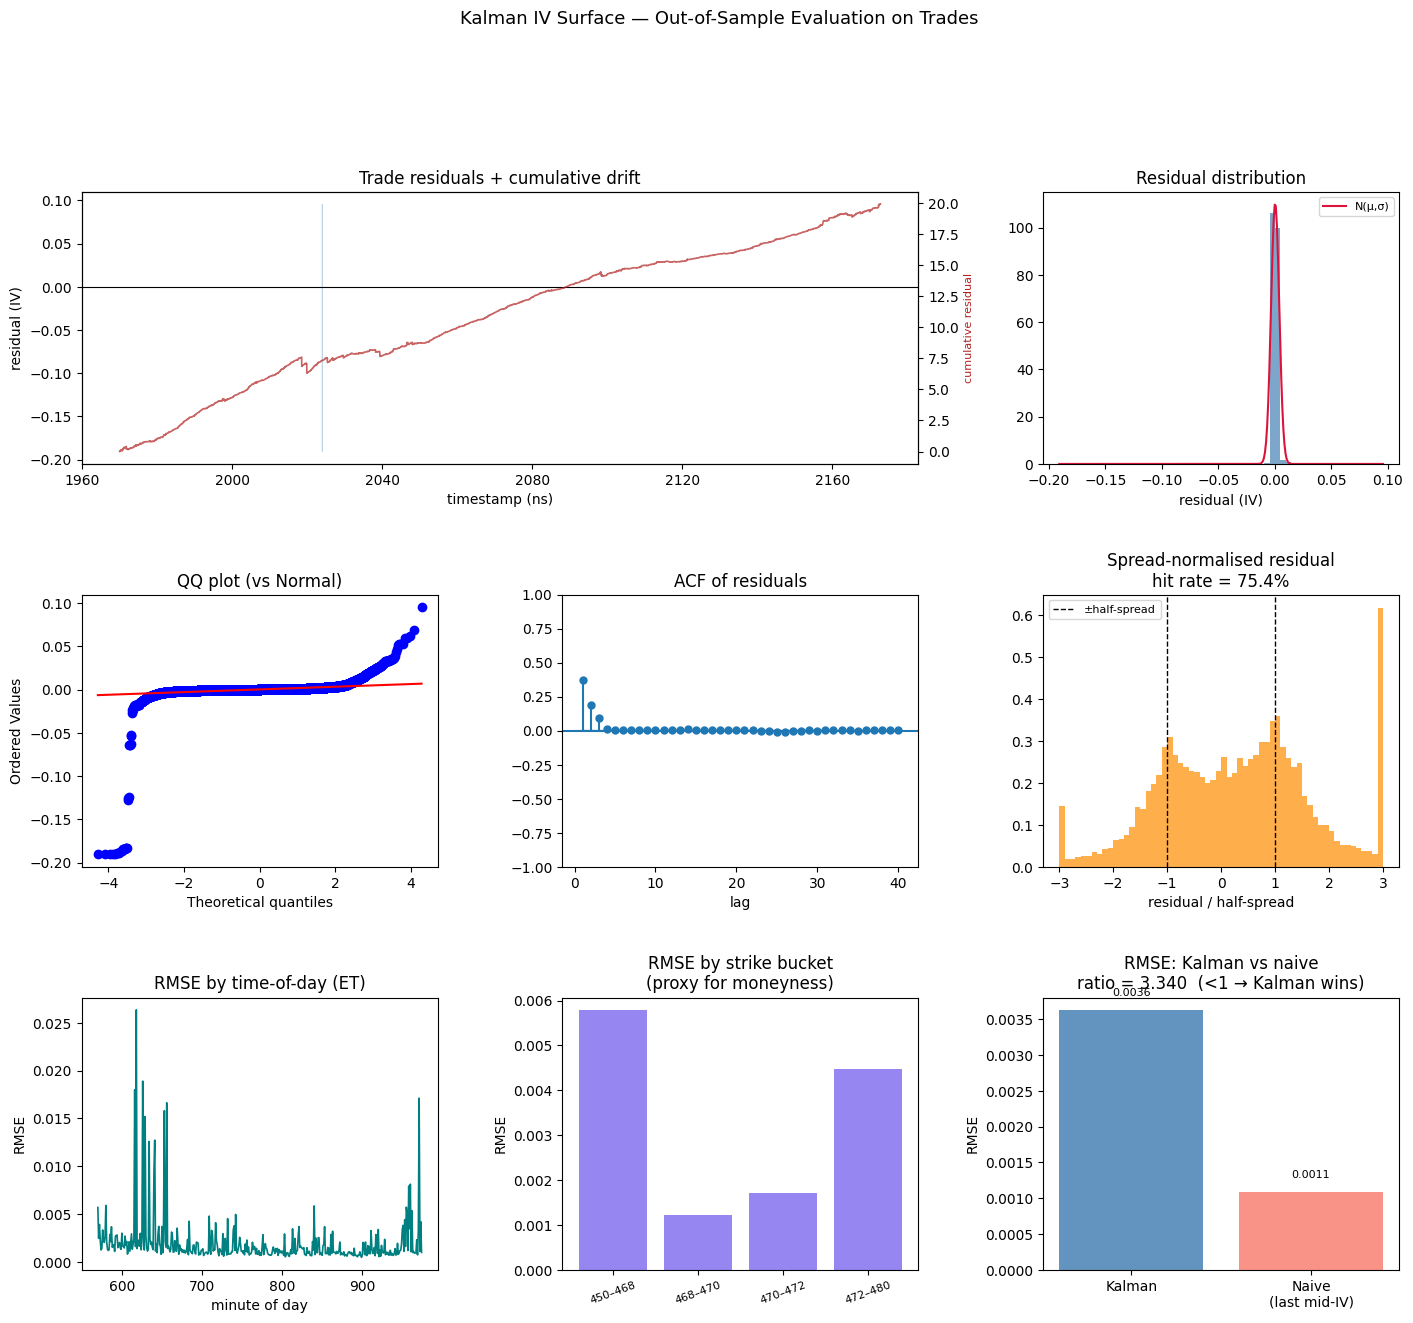

RMSE                 0.00362
MAE                  0.00090
Bias                 0.00027
Hit rate             75.4%
Naive RMSE           0.00108
RMSE ratio           3.340  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
         lb_stat  lb_pvalue
10  13900.333783        0.0
20  13927.337657        0.0


In [10]:
# evaluate_kalman_iv expects 'kalman_matched' column on trades — rename to reuse it
metrics = evaluate_kalman_iv(
    df_quotes_iv=df_quotes_result.rename({"spline_iv": "kalman_iv"}),
    df_trades_iv=df_trades_result.rename({"spline_matched": "kalman_matched"}),
)

## Compare vs individual per-option Kalman (baseline)

In [11]:
# Run the old filter for comparison
df_quotes_indiv, df_trades_indiv = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
df_trades_indiv_clean = df_trades_indiv.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_indiv = float((df_trades_indiv_clean["trade_residual"] ** 2).mean() ** 0.5)

print(f"Spline surface RMSE : {rmse:.5f}")
print(f"Individual KF RMSE  : {rmse_indiv:.5f}")
print(f"Ratio (spline/indiv): {rmse / rmse_indiv:.3f}  (<1 → spline wins)")

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [12]:
df_quotes_iv

ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,469.0,true,-0.000117,0.005447,0.134535,0.134132,0.134856,1.3110e-7,1.88,1.89,469.055
2024-01-03 16:14:59.884593152 EST,474.0,false,0.010487,0.005447,0.138451,0.132675,0.144803,0.000037,5.28,5.38,469.055
2024-01-03 16:14:59.884598272 EST,472.0,false,0.006259,0.005447,0.13324,0.131454,0.136743,0.000007,3.66,3.72,469.055


In [13]:
from plotly.subplots import make_subplots
from scipy.interpolate import UnivariateSpline

df_res = df_quotes_result.filter(
    pl.col("observed_iv").is_not_nan()
    & pl.col("observed_iv").is_not_null()
    & pl.col("spline_iv").is_not_nan()
    & pl.col("spline_iv").is_not_null()
    & pl.col("log_moneyness").is_not_nan()
    & pl.col("log_moneyness").is_not_null()
).with_columns((pl.col("observed_iv") - pl.col("spline_iv")).alias("residual"))

# Per-bin stats (0.5% buckets)
bin_w = 0.005
df_agg = (
    df_res.with_columns(((pl.col("log_moneyness") / bin_w).round(0) * bin_w).alias("k_center"))
    .group_by("k_center")
    .agg(
        pl.col("residual").mean().alias("mean"),
        pl.col("residual").std().alias("std"),
        pl.col("residual").count().alias("n"),
    )
    .filter(pl.col("n") >= 100)
    .sort("k_center")
)

k = df_agg["k_center"].to_numpy()
mu = df_agg["mean"].to_numpy()
sig = df_agg["std"].to_numpy()
w = np.sqrt(df_agg["n"].to_numpy())

# Weighted smoothing cubic spline (k=3), s controls smoothness
cs_fn = UnivariateSpline(k, mu, w=w, k=3, s=len(k))
k_dense = np.linspace(k.min(), k.max(), 400)

df_sample = df_res.sample(n=min(50_000, df_res.shape[0]), seed=0)
k_raw = df_sample["log_moneyness"].to_numpy()
r_raw = df_sample["residual"].to_numpy()

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    row_heights=[0.75, 0.25],
    vertical_spacing=0.04,
)

fig.add_trace(
    go.Scattergl(
        x=k_raw,
        y=r_raw,
        mode="markers",
        marker=dict(size=2, color="steelblue", opacity=0.15),
        name="raw quotes (50k sample)",
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=np.concatenate([k, k[::-1]]),
        y=np.concatenate([mu + sig, (mu - sig)[::-1]]),
        fill="toself",
        fillcolor="rgba(255,140,0,0.15)",
        line=dict(color="rgba(255,140,0,0)"),
        name="±1σ per bin",
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=k,
        y=mu,
        mode="markers",
        marker=dict(size=6, color="darkorange", symbol="circle"),
        name="bin mean",
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=k_dense,
        y=cs_fn(k_dense),
        mode="lines",
        line=dict(color="crimson", width=2),
        name="cubic spline (weighted, s=n_bins)",
    ),
    row=1,
    col=1,
)

fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"), row=1, col=1)

fig.add_trace(
    go.Bar(
        x=k,
        y=df_agg["n"].to_numpy(),
        marker_color="steelblue",
        opacity=0.6,
        name="n quotes",
        showlegend=False,
    ),
    row=2,
    col=1,
)

fig.update_layout(
    title="SVI Kalman residuals vs log-moneyness",
    height=600,
    legend=dict(x=0.01, y=0.99),
)
fig.update_yaxes(title_text="residual  (observed IV − SVI)", row=1, col=1)
fig.update_yaxes(title_text="n quotes", row=2, col=1)
fig.update_xaxes(title_text="log-moneyness  k = log(K/F)", row=2, col=1)
fig.show()

print(f"Global mean residual : {float(df_res['residual'].mean()):.6f}")
print(f"Global std  residual : {float(df_res['residual'].std()):.6f}")
print(f"Worst bin mean       : k={k[abs(mu).argmax()]:+.3f}  μ={mu[abs(mu).argmax()]:.6f}")
print(f"Cubic spline knots   : {cs_fn.get_knots().round(4)}")

Global mean residual : 0.000011
Global std  residual : 0.000160
Worst bin mean       : k=-0.045  μ=0.000297
Cubic spline knots   : [-0.045  0.025]


## Pass 2 – Residual Fit

Fit a correction term **Δ(k)** in relative-strike space so the final surface is  
**σ(k, T) = SVI(k, T; θ) + Δ(k)**

Δ(k) is calibrated to the time-averaged, per-strike residual of the SVI Kalman filter across the full trading session.  
Two functional forms are compared: a weighted **polynomial** (deg 4) and a **thin-plate-spline RBF**.

In [14]:
# Step 3 — per-observation residuals from all valid quotes
df_res = df_quotes_result.filter(
    pl.col("observed_iv").is_not_nan()
    & pl.col("observed_iv").is_not_null()
    & pl.col("spline_iv").is_not_nan()
    & pl.col("spline_iv").is_not_null()
    & pl.col("log_moneyness").is_not_nan()
    & pl.col("log_moneyness").is_not_null()
).with_columns((pl.col("observed_iv") - pl.col("spline_iv")).alias("residual"))
print(f"Clean quote rows: {df_res.shape[0]:,}")

# Bin into relative-strike buckets (bin_w ≈ 0.5% moneyness)
bin_w = 0.005
df_res_agg = (
    df_res.with_columns(((pl.col("log_moneyness") / bin_w).round(0) * bin_w).alias("k_center"))
    .group_by("k_center")
    .agg(
        pl.col("residual").mean().alias("mean_residual"),
        pl.col("residual").std().alias("std_residual"),
        pl.col("residual").count().alias("n"),
    )
    .filter(pl.col("n") >= 100)
    .sort("k_center")
)
print(f"Stable strike buckets: {df_res_agg.shape[0]}  (bin_width={bin_w})")
df_res_agg

Clean quote rows: 978,523
Stable strike buckets: 14  (bin_width=0.005)


k_center,mean_residual,std_residual,n
f64,f64,f64,u32
-0.045,0.000297,0.001377,2198
-0.04,0.000007,0.000043,896
-0.03,0.000095,0.000376,455
-0.025,0.00002,0.000154,25586
-0.02,0.000009,0.000099,44988
…,…,…,…
0.005,0.000007,0.000109,127796
0.01,0.00001,0.000137,133196
0.015,0.000014,0.000191,79234


In-sample RMSE — poly(deg 4): 0.000043  |  RBF: 0.000035  |  cubic spline: 0.000047


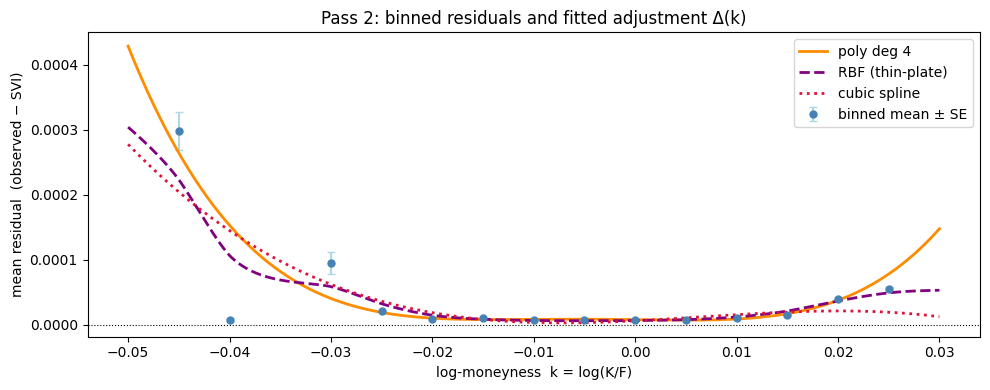

In [15]:
from scipy.interpolate import RBFInterpolator, UnivariateSpline

k_pts = df_res_agg["k_center"].to_numpy()
r_pts = df_res_agg["mean_residual"].to_numpy()
w_pts = np.sqrt(df_res_agg["n"].to_numpy())

# Weighted polynomial fit
poly_deg = 4
poly_coeffs = np.polyfit(k_pts, r_pts, poly_deg, w=w_pts)
poly_fn = np.poly1d(poly_coeffs)

# Thin-plate-spline RBF
_rbf = RBFInterpolator(k_pts[:, None], r_pts, kernel="thin_plate_spline", smoothing=1e-4)
rbf_fn = lambda k_arr: _rbf(np.asarray(k_arr)[:, None]).ravel()

# Weighted smoothing cubic spline
cs_fn = UnivariateSpline(k_pts, r_pts, w=w_pts, k=3, s=len(k_pts))

rmse_poly_is = float(np.sqrt(np.mean((r_pts - poly_fn(k_pts)) ** 2)))
rmse_rbf_is = float(np.sqrt(np.mean((r_pts - rbf_fn(k_pts)) ** 2)))
rmse_cs_is = float(np.sqrt(np.mean((r_pts - cs_fn(k_pts)) ** 2)))
print(
    f"In-sample RMSE — poly(deg {poly_deg}): {rmse_poly_is:.6f}  |  RBF: {rmse_rbf_is:.6f}  |  cubic spline: {rmse_cs_is:.6f}"
)

k_dense = np.linspace(k_pts.min() - 0.005, k_pts.max() + 0.005, 400)
se_pts = df_res_agg["std_residual"].to_numpy() / np.sqrt(df_res_agg["n"].to_numpy())

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(
    k_pts,
    r_pts,
    yerr=se_pts,
    fmt="o",
    ms=5,
    color="steelblue",
    ecolor="lightblue",
    capsize=3,
    label="binned mean ± SE",
)
ax.plot(k_dense, poly_fn(k_dense), "darkorange", lw=2, label=f"poly deg {poly_deg}")
ax.plot(k_dense, rbf_fn(k_dense), "purple", lw=2, ls="--", label="RBF (thin-plate)")
ax.plot(k_dense, cs_fn(k_dense), "crimson", lw=2, ls=":", label="cubic spline")
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("log-moneyness  k = log(K/F)")
ax.set_ylabel("mean residual  (observed − SVI)")
ax.set_title("Pass 2: binned residuals and fitted adjustment Δ(k)")
ax.legend()
plt.tight_layout()
plt.show()

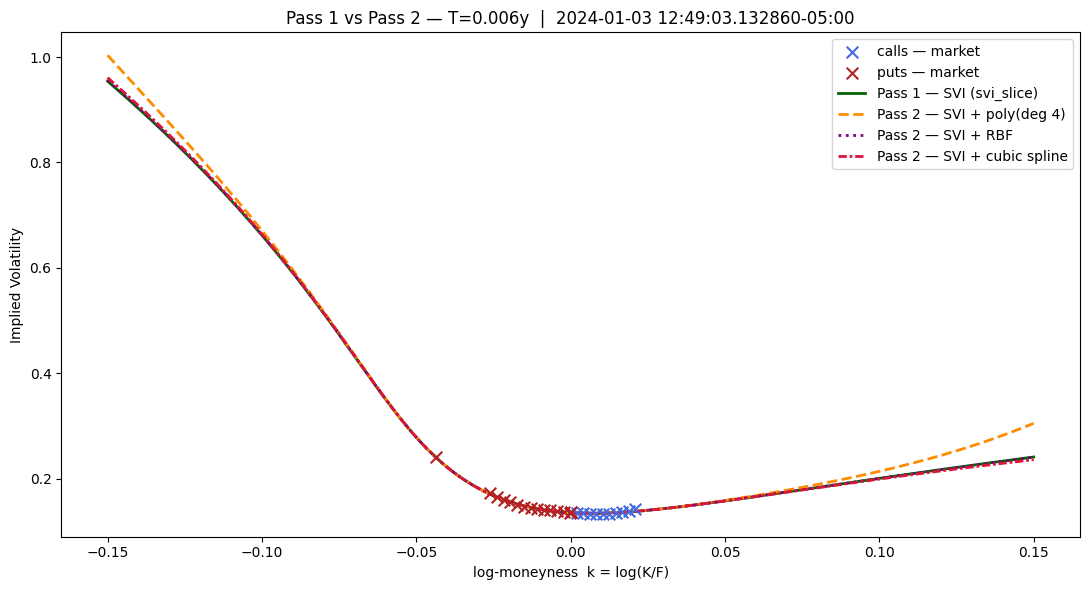

In [16]:
# Reuses: iv_fit, k_grid, snap_quotes, snap_T, snapshot_ts from snapshot cell above
iv_svi_poly = iv_fit + poly_fn(k_grid)
iv_svi_rbf = iv_fit + rbf_fn(k_grid)
iv_svi_cs = iv_fit + cs_fn(k_grid)

calls_snap = snap_quotes.filter(pl.col("is_call"))
puts_snap = snap_quotes.filter(~pl.col("is_call"))

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(
    calls_snap["log_moneyness"].to_numpy(),
    calls_snap["observed_iv"].to_numpy(),
    c="royalblue",
    marker="x",
    s=70,
    zorder=5,
    label="calls — market",
)
ax.scatter(
    puts_snap["log_moneyness"].to_numpy(),
    puts_snap["observed_iv"].to_numpy(),
    c="firebrick",
    marker="x",
    s=70,
    zorder=5,
    label="puts — market",
)
ax.plot(k_grid, iv_fit, "darkgreen", lw=2, label=f"Pass 1 — SVI ({cfg.model.name})")
ax.plot(
    k_grid, iv_svi_poly, "darkorange", lw=2, ls="--", label=f"Pass 2 — SVI + poly(deg {poly_deg})"
)
ax.plot(k_grid, iv_svi_rbf, "purple", lw=2, ls=":", label="Pass 2 — SVI + RBF")
ax.plot(
    k_grid, iv_svi_cs, "crimson", lw=2, ls=(0, (3, 1, 1, 1)), label="Pass 2 — SVI + cubic spline"
)

ax.set_xlabel("log-moneyness  k = log(K/F)")
ax.set_ylabel("Implied Volatility")
ax.set_title(f"Pass 1 vs Pass 2 — T={snap_T:.3f}y  |  {snapshot_ts}")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [17]:
k_trade = df_trades_clean["log_moneyness"].to_numpy()
res_base = df_trades_clean["trade_residual"].to_numpy()  # observed − SVI

rmse_svi = float(np.sqrt(np.mean(res_base**2)))
rmse_svi_poly = float(np.sqrt(np.mean((res_base - poly_fn(k_trade)) ** 2)))
rmse_svi_rbf = float(np.sqrt(np.mean((res_base - rbf_fn(k_trade)) ** 2)))
rmse_svi_cs = float(np.sqrt(np.mean((res_base - cs_fn(k_trade)) ** 2)))

print(f"{'Model':<32} {'RMSE':>10}   {'vs SVI':>10}")
print("-" * 56)
print(f"{'Individual KF (baseline)':<32} {rmse_indiv:>10.5f}")
print(f"{'Pass 1 — SVI Kalman':<32} {rmse_svi:>10.5f}   {'—':>10}")
print(
    f"{'Pass 2 — SVI + poly':<32} {rmse_svi_poly:>10.5f}   {(rmse_svi_poly / rmse_svi - 1) * 100:>+9.1f}%"
)
print(
    f"{'Pass 2 — SVI + RBF':<32} {rmse_svi_rbf:>10.5f}   {(rmse_svi_rbf / rmse_svi - 1) * 100:>+9.1f}%"
)
print(
    f"{'Pass 2 — SVI + cubic spline':<32} {rmse_svi_cs:>10.5f}   {(rmse_svi_cs / rmse_svi - 1) * 100:>+9.1f}%"
)

Model                                  RMSE       vs SVI
--------------------------------------------------------
Individual KF (baseline)            0.00274
Pass 1 — SVI Kalman                 0.00362            —
Pass 2 — SVI + poly                 0.00362        -0.0%
Pass 2 — SVI + RBF                  0.00362        -0.0%
Pass 2 — SVI + cubic spline         0.00362        -0.0%


In [18]:
print("=" * 65)
print("PASS 1 — SVI parameters (Kalman θ at end of session)")
print("=" * 65)
theta_final = np.array([df_state.tail(1)[f"theta_{j}"][0] for j in range(cfg.n_params)])
for name, val in zip(["a", "b", "rho", "m", "sigma"][: cfg.n_params], theta_final):
    print(f"  {name:>5} = {val: .6f}")

print()
print("=" * 65)
print(f"PASS 2 — Residual polynomial (degree {poly_deg})")
print("  σ(k, T) = SVI(k, T; θ) + Σ cᵢ·kⁱ    (highest power first)")
print("=" * 65)
for i, c in enumerate(poly_coeffs):
    print(f"  c_{poly_deg - i} (k^{poly_deg - i}) = {c: .6f}")

print()
print("=" * 65)
print("PASS 2 — RBF knot table  (thin-plate spline)")
print(f"  smoothing=1e-4   kernel=thin_plate_spline")
print("  k_centre  |  mean_residual")
print("=" * 65)
for k, r in zip(k_pts, r_pts):
    print(f"  {k:+.4f}   |  {r: .6f}")

print()
print("=" * 65)
print("PASS 2 — Cubic spline knots  (weighted UnivariateSpline, k=3)")
print(f"  s={len(k_pts)}")
print("  knot k  |  Δ(k)")
print("=" * 65)
for kn in cs_fn.get_knots():
    print(f"  {kn:+.4f}  |  {float(cs_fn(kn)): .6f}")

PASS 1 — SVI parameters (Kalman θ at end of session)
      a = -0.000050
      b =  0.024900
    rho = -0.950255
      m = -0.046979
  sigma =  0.018921

PASS 2 — Residual polynomial (degree 4)
  σ(k, T) = SVI(k, T; θ) + Σ cᵢ·kⁱ    (highest power first)
  c_4 (k^4) =  111.802949
  c_3 (k^3) =  2.202870
  c_2 (k^2) = -0.004793
  c_1 (k^1) = -0.000194
  c_0 (k^0) =  0.000008

PASS 2 — RBF knot table  (thin-plate spline)
  smoothing=1e-4   kernel=thin_plate_spline
  k_centre  |  mean_residual
  -0.0450   |   0.000297
  -0.0400   |   0.000007
  -0.0300   |   0.000095
  -0.0250   |   0.000020
  -0.0200   |   0.000009
  -0.0150   |   0.000010
  -0.0100   |   0.000007
  -0.0050   |   0.000007
  +0.0000   |   0.000007
  +0.0050   |   0.000007
  +0.0100   |   0.000010
  +0.0150   |   0.000014
  +0.0200   |   0.000039
  +0.0250   |   0.000055

PASS 2 — Cubic spline knots  (weighted UnivariateSpline, k=3)
  s=14
  knot k  |  Δ(k)
  -0.0450  |   0.000204
  +0.0250  |   0.000019
